# Hari 4: Evaluasi & Perbandingan Model
**Study Group I-Smile Lab: EDA to Machine Learning**
Jumat, 9 Oktober 2026 · Telkom University

### Tujuan hari ini
Setelah sesi ini kamu bisa:
1. Mengenali overfitting dan underfitting dengan membandingkan skor data latih dan data uji.
2. Menilai model dengan adil memakai cross-validation, bukan satu kali split.
3. Memilih nilai k dengan tuning (loop manual dan `GridSearchCV`).
4. Menjelaskan cara kerja Decision Tree, Random Forest, boosting, dan MLP dengan bahasa sederhana.
5. Membandingkan beberapa model dengan aturan yang sama, lalu memilih dengan mempertimbangkan metrik dan kebutuhan.

### Alur sesi
| Waktu | Bagian | Dataset |
|---|---|---|
| Pembukaan | 0. Persiapan (jalankan sebelum kelas dimulai) | A & B |
| Blok 1 | 1. Overfitting dan underfitting (8') | B |
| | 2. Cross-validation (15') | B |
| | 3. Tuning nilai k (10') | B |
| | 4. Decision Tree dan Random Forest (9') | B |
| | 5. Praktik: Decision Tree dan Random Forest untuk regresi (6') | A |
| | Buffer (2') | |
| Break | 10 menit | |
| Blok 2 | 6. Boosting: XGBoost dan LightGBM (7') | — |
| | 7. Neural Network (MLP) dan black box (6') | — |
| | 8. Perbandingan 6 model (12') | B |
| | Ringkasan dan Tugas 4 (± 1'), lalu buffer (± 4') | |
| | Brief Mini Project (20', dokumen terpisah) | |

Dataset A = harga rumah California (regresi, Hari 1–2). Dataset B = penyakit jantung (klasifikasi, Hari 3).

### Cara pakai notebook ini
1. Di Colab, pilih **File → Simpan salinan di Drive** supaya perubahanmu tersimpan di Drive sendiri.
2. Cari sel bertanda `# TODO`, lalu ganti setiap `___` dengan kode yang tepat.
3. Jalankan sel **setelah pengajar selesai menjelaskan slide** untuk topik itu. Selama pemaparan, cukup perhatikan dulu.
4. Jalankan sel **berurutan dari atas** dengan **Shift+Enter**. Kalau muncul error `NameError: name '...' is not defined`, berarti ada sel sebelumnya yang belum dijalankan (pakai menu *Runtime → Run before*).

Hari ini lebih banyak teori di slide. Sebagian besar sel di notebook adalah **demonstrasi** untuk membuktikan teori itu dengan angka.

Tanda yang dipakai di notebook ini:
- **Diskusi:** pertanyaan yang kita bahas bareng **sebelum** sel berikutnya dijalankan. Coba tebak dulu jawabannya.
- **Pengingat:** materi yang sudah dibahas di hari sebelumnya atau di slide. Jawabannya langsung ditulis, cukup dibaca.
- **Analogi:** perumpamaan sehari-hari, sama dengan yang ada di slide.
- Blockquote **Di dunia nyata**: versi lanjutan yang dipakai di industri. Cukup dipahami, tidak perlu dipraktikkan.

## 0. Persiapan (jalankan sebelum kelas dimulai)
Bagian ini menyiapkan **kedua dataset** persis seperti di hari sebelumnya, jadi tidak dibahas ulang. Jalankan semua sel di bagian ini begitu kamu datang.

In [ ]:
import pandas as pd               # mengolah tabel
import numpy as np                # operasi angka
import matplotlib.pyplot as plt   # membuat grafik

# membagi data, cross-validation, dan tuning
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline              # membungkus scaler + model jadi satu paket
from sklearn.preprocessing import StandardScaler        # menyamakan skala kolom (Hari 3)
from sklearn.neighbors import KNeighborsClassifier      # KNN (Hari 3)
from sklearn.linear_model import LinearRegression       # regresi linear (Hari 2)
# pohon keputusan untuk klasifikasi dan regresi, plus fungsi menggambarnya
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor   # banyak pohon sekaligus
from sklearn.neural_network import MLPClassifier        # neural network sederhana
from xgboost import XGBClassifier                       # boosting versi XGBoost
from lightgbm import LGBMClassifier                     # boosting versi LightGBM
# metrik klasifikasi (Hari 3)
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import r2_score, mean_absolute_error   # metrik regresi (Hari 2)

pd.set_option("display.max_columns", None)  # tampilkan semua kolom saat print tabel
plt.rcParams["figure.figsize"] = (8, 4.5)   # ukuran bawaan semua grafik

In [ ]:
# Lokasi dataset. Di Colab, ganti dengan link Google Drive, misalnya:
# DATA_PATH_A = "https://drive.google.com/uc?id=ISI_ID_FILE_DI_SINI"
DATA_PATH_A = "/content/housing_clean.csv"           # Dataset A: harga rumah (regresi)
DATA_PATH_B = "/content/heart_disease_uci.csv"   # Dataset B: penyakit jantung (klasifikasi)

### Dataset A (sama dengan Hari 2)

In [ ]:
df_a = pd.read_csv(DATA_PATH_A)   # file hasil export Hari 1, sudah bersih
# berhenti dengan pesan error kalau ukuran data salah (salah file)
assert df_a.shape == (20640, 13), f"Ukuran Dataset A {df_a.shape}, seharusnya (20640, 13). Cek lagi file-nya."

X_a = df_a.drop(columns="median_house_value")   # fitur: semua kolom kecuali harga
y_a = df_a["median_house_value"]                # target: harga rumah
# split sama persis dengan Hari 2
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(X_a, y_a, test_size=0.2, random_state=42)

### Cleaning Dataset B (sama dengan Hari 3, tidak dibahas ulang)

In [ ]:
df_b = pd.read_csv(DATA_PATH_B)   # file mentah, sama dengan Hari 3
# berhenti dengan pesan error kalau ukuran data salah (salah file)
assert df_b.shape == (920, 16), f"Ukuran Dataset B {df_b.shape}, seharusnya (920, 16). Cek lagi file-nya."

df_clean_b = df_b.drop(columns=["ca", "thal", "slope"])           # kolom yang kosong lebih dari 1/3
for kolom in ["chol", "trestbps"]:                                # kolom dengan missing tersamar
    df_clean_b.loc[df_clean_b[kolom] == 0, kolom] = np.nan        # nilai 0 jadi kosong
for kolom in ["trestbps", "chol", "thalch", "oldpeak"]:           # kolom angka
    nilai_isi = df_clean_b[kolom].median()                        # nilai tengah kolom
    df_clean_b.loc[df_clean_b[kolom].isnull(), kolom] = nilai_isi  # isi yang kosong dengan median
for kolom in ["fbs", "restecg", "exang"]:                         # kolom kategori
    nilai_isi = df_clean_b[kolom].mode()[0]                       # nilai yang paling sering
    df_clean_b.loc[df_clean_b[kolom].isnull(), kolom] = nilai_isi  # isi yang kosong dengan modus
df_clean_b = df_clean_b.drop(columns="id")                        # nomor urut, bukan gejala
df_clean_b["target"] = (df_clean_b["num"] > 0).astype(int)        # 1 = sakit, 0 = sehat
df_clean_b["sex"] = (df_clean_b["sex"] == "Male").astype(int)     # Male = 1, Female = 0
df_clean_b["fbs"] = df_clean_b["fbs"].astype(int)                 # True = 1, False = 0
df_clean_b["exang"] = df_clean_b["exang"].astype(int)             # True = 1, False = 0
# one-hot untuk kategori yang tidak berurutan
df_clean_b = pd.get_dummies(df_clean_b, columns=["cp", "restecg"], drop_first=True, dtype=int)

X_b = df_clean_b.drop(columns=["num", "target", "dataset"])   # 13 fitur, sama dengan Hari 3
y_b = df_clean_b["target"]                                     # target 0/1
assert X_b.shape == (920, 13), f"Ukuran X_b {X_b.shape}, seharusnya (920, 13)."   # cek hasil cleaning

### Split dan scaling Dataset B (sama dengan Hari 3)

In [ ]:
# split sama persis dengan Hari 3
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_b, y_b, test_size=0.2, random_state=42, stratify=y_b)

scaler_b = StandardScaler()                        # scaler seperti Hari 3
scaler_b.fit(X_train_b)                            # hitung mean dan std dari data latih saja
X_train_b_scaled = scaler_b.transform(X_train_b)   # data latih yang sudah di-scaling
X_test_b_scaled = scaler_b.transform(X_test_b)     # data uji dengan mean dan std yang sama

In [ ]:
print("Dataset A (regresi)    : X_train", X_train_a.shape, "| X_test", X_test_a.shape)
print("                         y_train", y_train_a.shape, "| y_test", y_test_a.shape)
print("Dataset B (klasifikasi): X_train", X_train_b.shape, "| X_test", X_test_b.shape)
print("                         y_train", y_train_b.shape, "| y_test", y_test_b.shape)
print("Data uji B:", (y_test_b == 1).sum(), "sakit,", (y_test_b == 0).sum(), "sehat")

Dataset A (regresi)    : X_train (16512, 12) | X_test (4128, 12)
                         y_train (16512,) | y_test (4128,)
Dataset B (klasifikasi): X_train (736, 13) | X_test (184, 13)
                         y_train (736,) | y_test (184,)
Data uji B: 102 sakit, 82 sehat


---
# Blok 1: Menilai model dengan adil (± 50 menit)
Sejak Hari 2 kita selalu menilai model di data uji. Hari ini kita bertanya lebih jauh: **apakah satu kali penilaian itu sudah adil?** Dan kalau ada beberapa pilihan model atau pengaturan, **bagaimana memilihnya tanpa mengintip data uji?**

## 1. Overfitting dan underfitting (± 8 menit)
- **Overfitting**: skor di data latih tinggi, tapi skor di data uji jauh lebih rendah. Model **menghafal** data latih, bukan memahami polanya.
- **Underfitting**: skor di data latih dan data uji **sama-sama rendah**. Model terlalu sederhana untuk menangkap pola.

**Analogi:** Siswa yang menghafal kunci jawaban latihan: nilai latihannya 100, tapi gagal saat soalnya diganti.

**Analogi:** Siswa yang menjawab "C" untuk semua soal: tidak ada yang dihafal, tapi juga tidak ada yang dipahami.

Cara mengeceknya: bandingkan skor di **data latih** dan **data uji**. Skor data latih sengaja kita sembunyikan sejak Hari 2, supaya fokus ke data uji dulu. Hari ini, untuk pertama kalinya, kita tampilkan keduanya berdampingan. Kita pakai KNN dari Hari 3 dengan empat nilai k, dari yang sangat kecil sampai hampir seluruh data latih (736 baris).

In [ ]:
hasil_fit = []                                       # tempat menyimpan hasil tiap k
for k in [1, 5, 51, 735]:                            # dari sangat kecil sampai hampir seluruh data latih
    knn = KNeighborsClassifier(n_neighbors=k)        # KNN dengan k tetangga
    knn.fit(X_train_b_scaled, y_train_b)             # simpan data latih
    acc_train = accuracy_score(y_train_b, knn.predict(X_train_b_scaled))   # menebak data yang sudah dilihat
    acc_test = accuracy_score(y_test_b, knn.predict(X_test_b_scaled))      # menebak data baru
    hasil_fit.append({"k": k, "akurasi train": acc_train, "akurasi test": acc_test,   # satu baris tabel
                      "selisih": acc_train - acc_test})                               # train dikurangi test

tabel_fit = pd.DataFrame(hasil_fit)                  # daftar hasil jadi tabel
# tampilkan sebagai persen 1 desimal, tanpa nomor baris
tabel_fit.style.format({"akurasi train": "{:.1%}", "akurasi test": "{:.1%}", "selisih": "{:.1%}"}).hide(axis="index")

k,akurasi train,akurasi test,selisih
1,100.0%,74.5%,25.5%
5,82.9%,82.6%,0.3%
51,81.7%,80.4%,1.2%
735,55.3%,55.4%,-0.1%


**Diskusi:** k = 1 akurasi latihnya hampir 100%. Kenapa?

**Diskusi:** k = 735 skornya mirip baseline Hari 3. Kenapa?

**Pengingat:** di Hari 3 kita sudah melihat k = 1 lebih jelek dari k = 5 di data uji. Hari ini terlihat alasannya: k = 1 menghafal data latih (overfitting).

## 2. Cross-validation (± 15 menit)
### 2a. Masalah satu kali split (± 4 menit)
Sejak Hari 2 kita membagi data **satu kali** dengan `random_state=42`. Bagaimana kalau cara mengacaknya diganti?

**Analogi:** Nilai satu kali ujian bisa tinggi karena kebetulan soalnya gampang.

Mulai sekarang, scaler dan KNN kita bungkus jadi **satu paket** dengan `make_pipeline`. Setiap kali data dibagi ulang, scaler harus belajar ulang hanya dari data latih potongan itu (alasannya sama dengan `fit` hanya di `X_train` di Hari 3), dan paket ini mengerjakannya otomatis: `fit` menjalankan scaler lalu KNN, `predict` juga.

**Analogi:** Mesin kopi satu tombol: menggiling dan menyeduh selalu berurutan, jadi urutannya tidak mungkin tertukar.

In [ ]:
pipeline_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))   # paket: scaling lalu KNN
pipeline_knn   # tampilkan isi paketnya

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('kneighborsclassifier', KNeighborsClassifier())])

In [ ]:
akurasi_per_split = {}                                # random_state -> akurasi test
for rs in range(10):                                  # 10 cara mengacak yang berbeda
    # split ulang dengan random_state berbeda, proporsi kelas tetap dijaga
    X_latih_rs, X_uji_rs, y_latih_rs, y_uji_rs = train_test_split(X_b, y_b, test_size=0.2, random_state=rs, stratify=y_b)
    pipeline_knn.fit(X_latih_rs, y_latih_rs)          # scaler + KNN belajar dari potongan latih ini saja
    akurasi_per_split[f"random_state={rs}"] = accuracy_score(y_uji_rs, pipeline_knn.predict(X_uji_rs))   # nilai di potongan uji

akurasi_split = pd.Series(akurasi_per_split)          # 10 akurasi jadi satu kolom
ringkasan_split = pd.Series({"min": akurasi_split.min(),                                  # akurasi terendah
                             "max": akurasi_split.max(),                                  # akurasi tertinggi
                             "selisih (max - min)": akurasi_split.max() - akurasi_split.min()})   # rentang naik-turun
# gabungkan 10 baris + 3 baris ringkasan, tampilkan sebagai persen
pd.concat([akurasi_split, ringkasan_split]).to_frame("akurasi test").style.format("{:.1%}")

,akurasi test
random_state=0,82.6%
random_state=1,77.7%
random_state=2,77.2%
random_state=3,75.5%
random_state=4,81.0%
random_state=5,79.3%
random_state=6,80.4%
random_state=7,73.9%
random_state=8,81.0%
random_state=9,75.5%


**Diskusi:** Di Tugas 3, tiap kelompok memilih k berdasarkan skor data uji. Kalau skor bisa berubah sekian poin hanya karena ganti `random_state`, pilihan k itu bisa dipercaya?

### 2b. Cara kerja k-fold cross-validation (± 4 menit)
**Analogi:** Ujian 5 kali dengan paket soal berbeda, lalu nilainya dirata-rata. Setiap soal pernah jadi soal ujian tepat satu kali.

Contoh dengan data latih kita (736 baris) dan 5 lipatan (*fold*):
1. Data latih dibagi menjadi 5 lipatan, masing-masing ± 147 baris.
2. Model dilatih **5 kali**. Setiap kali, 4 lipatan dipakai untuk latihan dan 1 lipatan sisanya untuk **validasi** (ujian kecil).
3. Hasilnya 5 skor, lalu dirata-rata.

```
Putaran 1:  [VALIDASI] [ latih  ] [ latih  ] [ latih  ] [ latih  ]   -> skor 1
Putaran 2:  [ latih  ] [VALIDASI] [ latih  ] [ latih  ] [ latih  ]   -> skor 2
Putaran 3:  [ latih  ] [ latih  ] [VALIDASI] [ latih  ] [ latih  ]   -> skor 3
Putaran 4:  [ latih  ] [ latih  ] [ latih  ] [VALIDASI] [ latih  ]   -> skor 4
Putaran 5:  [ latih  ] [ latih  ] [ latih  ] [ latih  ] [VALIDASI]   -> skor 5
```

Data uji (`X_test_b`, 184 baris) **tidak ikut** sama sekali. Ia disimpan sebagai ujian akhir.

### 2c. `cross_val_score` (± 7 menit)
`cross_val_score` mengerjakan kelima putaran di atas dalam satu baris. Karena yang dimasukkan adalah **paket** scaler + KNN, scaler ikut belajar ulang di setiap putaran, hanya dari 4 lipatan latihannya.

In [ ]:
# TODO: jalankan cross-validation 5 lipatan untuk paket scaler + KNN (k=5) dari 2a
scores = cross_val_score(pipeline_knn, X_train_b, y_train_b, cv=5, scoring="accuracy")   # 5 kali latih-validasi

print("Akurasi tiap lipatan:", [f"{s:.1%}" for s in scores])
print(f"Rata-rata          : {scores.mean():.1%}")
print(f"Standar deviasi    : {scores.std():.1%}")

Akurasi tiap lipatan: ['79.1%', '84.4%', '76.9%', '72.8%', '76.9%']
Rata-rata          : 78.0%
Standar deviasi    : 3.8%


**Diskusi:** Kenapa cross-validation dijalankan di `X_train_b`, bukan di seluruh data?

**Diskusi:** Standar deviasinya kecil atau besar? Artinya apa?

> **Di dunia nyata (cukup dipahami, tidak dipraktikkan):** `cv=5` pada model klasifikasi otomatis memakai `StratifiedKFold`, yaitu proporsi kelas di tiap lipatan dijaga sama, seperti `stratify` di Hari 3. Untuk data kecil sering dipakai `cv=10`, atau cross-validation yang diulang beberapa kali dengan pengacakan berbeda.

## 3. Tuning nilai k (± 10 menit)
**Tuning** artinya mencoba beberapa nilai pengaturan model, lalu memilih yang skornya terbaik. Bedanya dengan Tugas 3: skor yang dipakai untuk memilih sekarang adalah **skor cross-validation**, bukan skor data uji.

**Analogi:** Mencoba beberapa takaran gula, lalu setiap takaran dinilai oleh 5 juri yang sama.

### 3a. Tuning manual (± 6 menit)

In [ ]:
hasil_tuning = []                                     # tempat menyimpan hasil tiap k
for k in range(1, 32, 2):                             # k ganjil 1, 3, 5, ..., 31
    model_k = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))   # paket dengan k tetangga
    # TODO: hitung rata-rata akurasi cross-validation 5 lipatan untuk paket model_k
    cv_mean = cross_val_score(model_k, X_train_b, y_train_b, cv=5).mean()   # rata-rata 5 lipatan
    hasil_tuning.append({"k": k, "akurasi CV": cv_mean})   # simpan sebagai satu baris

tabel_tuning = pd.DataFrame(hasil_tuning)             # daftar hasil jadi tabel
k_terbaik = int(tabel_tuning.loc[tabel_tuning["akurasi CV"].idxmax(), "k"])   # k dengan akurasi CV tertinggi
print("k terbaik menurut cross-validation:", k_terbaik)
print(f"Akurasi CV-nya                    : {tabel_tuning['akurasi CV'].max():.1%}")

k terbaik menurut cross-validation: 23
Akurasi CV-nya                    : 81.5%


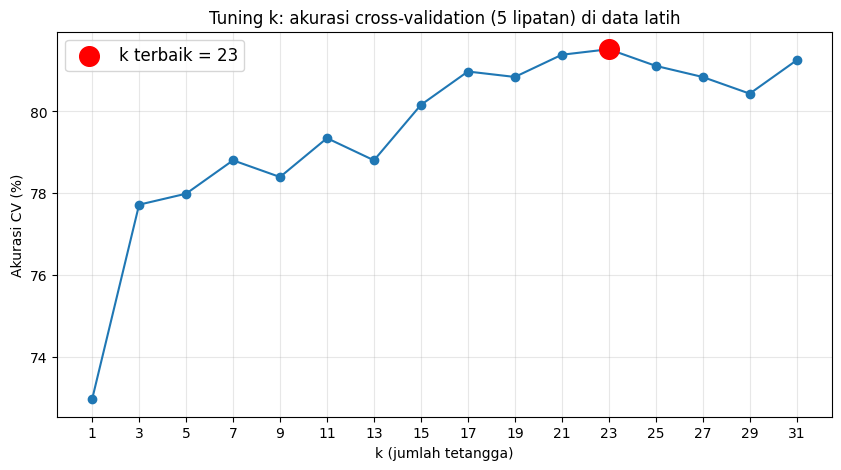

In [ ]:
baris_terbaik = tabel_tuning[tabel_tuning["k"] == k_terbaik]   # baris k terbaik, untuk ditandai

plt.figure(figsize=(10, 5))
plt.plot(tabel_tuning["k"], tabel_tuning["akurasi CV"] * 100, marker="o")   # garis k vs akurasi CV (%)
plt.scatter(baris_terbaik["k"], baris_terbaik["akurasi CV"] * 100, color="red", s=200, zorder=3,
            label=f"k terbaik = {k_terbaik}")                              # titik merah = k terbaik
plt.xticks(tabel_tuning["k"])                                              # tampilkan semua nilai k
plt.title("Tuning k: akurasi cross-validation (5 lipatan) di data latih")
plt.xlabel("k (jumlah tetangga)")
plt.ylabel("Akurasi CV (%)")
plt.grid(alpha=0.3)
plt.legend(fontsize=12)
plt.show()

Sekarang k terbaik dilatih di **seluruh** data latih, lalu dinilai **sekali** di data uji. Kita bandingkan dengan k = 5 dari Hari 3.

In [ ]:
hasil_banding = []                                    # k=5 (Hari 3) vs k terbaik (Hari 4)
for asal, k in [("Hari 3 (k = 5)", 5), ("Hari 4 (k terbaik CV)", k_terbaik)]:   # dua nilai k yang dibandingkan
    model_k = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))   # paket dengan k tetangga
    model_k.fit(X_train_b, y_train_b)                 # latih di seluruh data latih
    cv_k = tabel_tuning.loc[tabel_tuning["k"] == k, "akurasi CV"].iloc[0]   # ambil skor CV dari tabel tuning
    acc_test_k = accuracy_score(y_test_b, model_k.predict(X_test_b))       # ujian akhir, dibuka sekali
    hasil_banding.append({"model": asal, "k": k, "akurasi CV": cv_k, "akurasi test": acc_test_k})   # satu baris

# tampilkan sebagai persen 1 desimal, tanpa nomor baris
pd.DataFrame(hasil_banding).style.format({"akurasi CV": "{:.1%}", "akurasi test": "{:.1%}"}).hide(axis="index")

model,k,akurasi CV,akurasi test
Hari 3 (k = 5),5,78.0%,82.6%
Hari 4 (k terbaik CV),23,81.5%,79.9%


Perhatikan: di data uji, k = 5 justru sedikit lebih tinggi. Ini tidak berarti tuning gagal. Ingat 2a: skor satu data uji bisa naik-turun beberapa poin karena kebetulan, sedangkan skor CV adalah rata-rata dari 5 penilaian. Untuk **memilih**, kita percaya skor CV. Data uji hanya dipakai untuk melaporkan hasil akhir, bukan untuk memilih ulang.

**Pengingat:** nilai k yang dicoba ganjil semua karena hanya ada dua kelas. Dengan k ganjil voting tidak mungkin seri (Hari 3).

### 3b. GridSearchCV (± 4 menit)
Loop di 3a sangat sering dipakai, jadi scikit-learn menyediakan versi otomatisnya: `GridSearchCV`. Kita beri daftar nilai yang mau dicoba, lalu ia menjalankan cross-validation untuk setiap nilai dan memilih yang terbaik.

**Analogi:** Mesin cuci otomatis: langkahnya sama dengan mencuci manual, hanya dikerjakan mesin.

In [ ]:
# nama parameter = nama langkah di pipeline + dua garis bawah (__) + nama parameter
param_grid = {"kneighborsclassifier__n_neighbors": list(range(1, 32, 2))}   # 16 nilai k yang dicoba

grid = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),   # paket yang di-tuning
                    param_grid, cv=5, scoring="accuracy")                      # aturan sama dengan loop 3a
grid.fit(X_train_b, y_train_b)   # 16 nilai k x 5 lipatan = 80 kali latihan

k_grid = grid.best_params_["kneighborsclassifier__n_neighbors"]   # k terbaik versi GridSearch
print("best_params_:", grid.best_params_)
print(f"best_score_ : {grid.best_score_:.1%}")
print(f"Manual (3a) : k = {k_terbaik}, akurasi CV {tabel_tuning['akurasi CV'].max():.1%}")
print(f"GridSearch  : k = {k_grid}, akurasi CV {grid.best_score_:.1%}")

best_params_: {'kneighborsclassifier__n_neighbors': 23}
best_score_ : 81.5%
Manual (3a) : k = 23, akurasi CV 81.5%
GridSearch  : k = 23, akurasi CV 81.5%


**Diskusi:** GridSearch memberi k yang sama dengan loop kita. Jadi sebenarnya apa yang dikerjakan GridSearch?

> **Di dunia nyata (cukup dipahami, tidak dipraktikkan):** Untuk deteksi penyakit, tuning sering memakai `scoring="recall"`, bukan accuracy, supaya yang dicari adalah model yang paling sedikit melewatkan pasien sakit. Kalau kombinasi pengaturannya sangat banyak, dipakai `RandomizedSearchCV`, yang hanya mencoba sebagian kombinasi secara acak.

## 4. Decision Tree dan Random Forest (± 9 menit)
### Decision Tree
Decision Tree menebak dengan serangkaian pertanyaan ya/tidak. Setiap pertanyaan membandingkan **satu kolom** dengan **satu angka batas**, misalnya "`thalch` <= 150,5?". Pertanyaan dipilih yang paling baik memisahkan pasien sakit dan sehat.

**Analogi:** Dokter yang bertanya ya/tidak secara berurutan: "Umur di atas 55?" → "Nyeri dada tanpa gejala?" → "Sakit".

Kita buat pohon kecil, hanya 2 tingkat pertanyaan, supaya bisa dibaca.

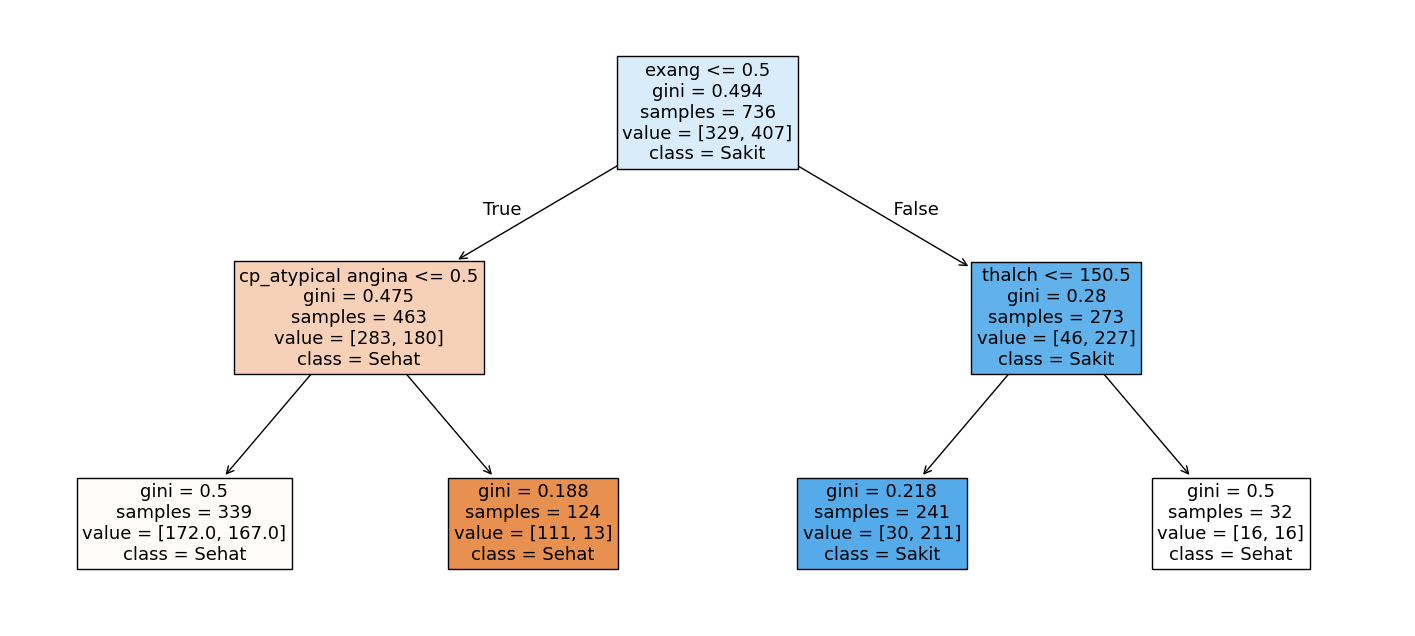

In [ ]:
pohon_kecil = DecisionTreeClassifier(max_depth=2, random_state=42)   # maksimal 2 tingkat pertanyaan
pohon_kecil.fit(X_train_b, y_train_b)                                # cari pertanyaan terbaik (data tanpa scaling)

plt.figure(figsize=(18, 8))                                          # besar supaya terbaca dari proyektor
# gambar pohon: nama kolom, nama kelas, warna sesuai kelas terbanyak di tiap kotak
plot_tree(pohon_kecil, feature_names=list(X_train_b.columns), class_names=["Sehat", "Sakit"], filled=True, fontsize=13)
plt.show()

**Diskusi:** Baca pohonnya: pertanyaan pertama yang ditanyakan model apa? Masuk akal secara medis?

**Pengingat:** Decision Tree tidak butuh scaling, karena setiap pertanyaan hanya membandingkan satu kolom dengan satu angka batas (sudah disebut di "Di dunia nyata" Hari 3). Itu sebabnya pohon di atas dilatih dengan `X_train_b` mentah.

### Random Forest
Satu pohon mudah menghafal. Random Forest membuat **banyak pohon**, dan setiap pohon dilatih dengan **sebagian pasien** (diambil acak) dan hanya boleh memakai **sebagian kolom** di setiap pertanyaan. Karena tiap pohon melihat data yang sedikit berbeda, kesalahannya juga berbeda-beda, dan saat digabung kesalahan itu saling menutupi.

**Analogi:** Bertanya ke 100 dokter. Tiap dokter hanya melihat sebagian pasien dan sebagian gejala, lalu semua voting.

Contoh dengan 5 pohon untuk satu pasien:

| Pohon 1 | Pohon 2 | Pohon 3 | Pohon 4 | Pohon 5 | Hasil akhir |
|---|---|---|---|---|---|
| Sakit | Sehat | Sakit | Sakit | Sehat | **Sakit** (3 lawan 2) |

Untuk **regresi**, tebakan semua pohon **dirata-rata**. Misalnya 5 pohon menebak harga 200, 220, 210, 190, 230 (ribu USD), hasil akhirnya 210 ribu USD.

## 5. Praktik: Decision Tree dan Random Forest untuk regresi (± 6 menit)
Di Hari 2 kita melihat Random Forest jauh lebih baik dari regresi linear, tapi belum tahu kenapa. Sekarang kita pakai Dataset A dengan split yang sama persis, dan bandingkan tiga model: regresi linear, **satu** pohon yang dibiarkan tumbuh tanpa batas, dan Random Forest (100 pohon).

Sel ini butuh beberapa detik karena Random Forest melatih 100 pohon. Tunggu sampai selesai, jangan dijalankan dua kali.

In [ ]:
model_regresi = {                                                       # data dan split sama dengan Hari 2
    "Linear Regression": LinearRegression(),                            # model Hari 2
    "Decision Tree": DecisionTreeRegressor(random_state=42),            # satu pohon, tanpa batas kedalaman
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),   # 100 pohon, dirata-rata
}

hasil_regresi = []                                                      # tempat menyimpan hasil tiap model
for nama, model in model_regresi.items():                               # latih dan nilai tiap model
    model.fit(X_train_a, y_train_a)                                     # latih di data latih A
    r2_train = r2_score(y_train_a, model.predict(X_train_a))            # skor di data yang sudah dilihat
    pred_test = model.predict(X_test_a)                                 # tebak data uji A
    r2_test = r2_score(y_test_a, pred_test)                             # skor di data baru
    hasil_regresi.append({"model": nama, "R² train": r2_train, "R² test": r2_test,          # satu baris tabel
                          "MAE test": mean_absolute_error(y_test_a, pred_test),             # rata-rata meleset (USD)
                          "selisih R²": r2_train - r2_test})                                # train dikurangi test

tabel_regresi = pd.DataFrame(hasil_regresi)                             # daftar hasil jadi tabel
# beri tanda pada model dengan R² test tertinggi
tabel_regresi["catatan"] = np.where(tabel_regresi["R² test"] == tabel_regresi["R² test"].max(), "terbaik", "")
format_regresi = {"R² train": "{:.3f}", "R² test": "{:.3f}", "MAE test": "{:,.0f}", "selisih R²": "{:.3f}"}   # R² 3 desimal, MAE ribuan
tabel_regresi.style.format(format_regresi).hide(axis="index")   # tampilkan tanpa nomor baris

model,R² train,R² test,MAE test,selisih R²,catatan
Linear Regression,0.649,0.631,"50,394",0.018,
Decision Tree,1.000,0.628,"43,991",0.372,
Random Forest,0.976,0.812,"32,128",0.164,terbaik


**Diskusi:** Decision Tree R² latihnya 1,000, tapi R² ujinya turun jauh. Apa yang terjadi?

**Diskusi:** Random Forest juga punya selisih train dan test. Jadi ia juga overfit? Kenapa tetap yang terbaik?

> **Di dunia nyata (cukup dipahami, tidak dipraktikkan):** Kedalaman pohon (`max_depth`) dan jumlah pohon (`n_estimators`) juga di-tuning dengan cross-validation, persis seperti k di Bagian 3.

---
# Break (10 menit)
Istirahat dulu. Pastikan semua sel di atas sudah jalan tanpa error sebelum lanjut. Bagian 8 memakai `k_terbaik` dari Bagian 3.

---

# Blok 2: Model lain dan cara memilihnya (± 30 menit)
Setelah bagian ini, 20 menit terakhir dipakai untuk **brief Mini Project** (dokumen terpisah).

## 6. Boosting: XGBoost dan LightGBM (± 7 menit)
Random Forest membuat banyak pohon **bersamaan** dan saling lepas. **Boosting** membuat pohon **satu per satu**, dan setiap pohon baru hanya bertugas memperbaiki kesalahan gabungan pohon-pohon sebelumnya.

**Analogi:** Siswa yang belajar dari soal yang salah: setiap pohon baru fokus memperbaiki kesalahan pohon sebelumnya. Random Forest itu voting beramai-ramai, boosting itu estafet.

Contoh menebak harga rumah yang aslinya **300** (ribu USD):

| Langkah | Yang ditebak pohon ini | Total tebakan | Sisa kesalahan |
|---|---|---|---|
| Pohon 1 | harga: 250 | 250 | 50 |
| Pohon 2 | sisa kesalahan: +40 | 290 | 10 |
| Pohon 3 | sisa kesalahan: +8 | 298 | 2 |

Sisa kesalahannya mengecil: 50 → 10 → 2. Pohon 2 dan 3 tidak menebak harga, tapi menebak **berapa yang masih kurang**.

| | Random Forest | Boosting |
|---|---|---|
| Cara pohon dibuat | Bersamaan, saling lepas | Berurutan, saling memperbaiki |
| Cara menggabungkan | Voting (klasifikasi) / rata-rata (regresi) | Hasil semua pohon dijumlahkan |

**XGBoost** dan **LightGBM** sama-sama boosting. Cara kerjanya sama; LightGBM dirancang supaya lebih cepat untuk data besar.

## 7. Neural Network (MLP) dan black box (± 6 menit)
**MLP** (*Multi-Layer Perceptron*) adalah neural network paling sederhana. Ia tersusun dari banyak **neuron** yang disusun berlapis.

**Analogi:** Juri bertingkat: juri lapis pertama menilai data mentah, juri lapis berikutnya menggabungkan penilaian mereka.

Satu neuron = **regresi linear Hari 2** + sebuah **"saklar"**. Saklar yang paling umum adalah **ReLU**: kalau hasilnya negatif, diubah menjadi 0.

Contoh satu neuron dengan dua kolom:

$$z = 0{,}5 \times \text{age} + 0{,}3 \times \text{chol} - 100$$

$$\text{ReLU}(z) = \max(0, z)$$

In [ ]:
pasien_buatan = pd.DataFrame({"age": [60, 40], "chol": [250, 180]}, index=["Pasien 1", "Pasien 2"])   # dua pasien buatan
z = 0.5 * pasien_buatan["age"] + 0.3 * pasien_buatan["chol"] - 100   # bobot x nilai + bias, seperti regresi linear
hasil_neuron = np.maximum(0, z)                                       # saklar ReLU: hasil negatif jadi 0
pd.DataFrame({"z": z, "setelah ReLU": hasil_neuron})                  # bandingkan sebelum dan sesudah saklar

,z,setelah ReLU
Pasien 1,5.0,5.0
Pasien 2,-26.0,0.0


Pasien 1: z = 30 + 75 − 100 = 5, positif, jadi diteruskan apa adanya. Pasien 2: z = 20 + 54 − 100 = −26, negatif, jadi saklar mengubahnya menjadi 0. MLP berisi ratusan neuron seperti ini, dan bobotnya (0,5; 0,3; −100) dicari sendiri saat `fit`.

**Pengingat:** MLP menghitung dengan bobot yang dikalikan langsung dengan nilai kolom, jadi seperti KNN, ia butuh scaling. Di Bagian 8, MLP dibungkus dalam pipeline bersama `StandardScaler`.

### White box vs black box
Model **white box** bisa dijelaskan alasannya. Model **black box** bisa memberi tebakan, tapi alasannya sulit dijelaskan ke manusia.

**Analogi:** Bisa memberi jawaban yang benar, tapi tidak bisa menjelaskan alasannya.

| Model | Bisa dijelaskan? | Caranya |
|---|---|---|
| KNN | Ya | Tunjukkan pasien-pasien termirip yang ikut voting |
| Decision Tree | Ya | Baca pertanyaan-pertanyaan di pohonnya (Bagian 4) |
| Random Forest, XGBoost, LightGBM | Sebagian | Hanya tahu kolom mana yang paling berpengaruh, karena pohonnya ratusan |
| MLP | Tidak | Ratusan bobot yang saling terhubung, tidak bisa dibaca satu per satu |

## 8. Perbandingan 6 model (± 12 menit)
Semua model dinilai dengan **aturan yang sama**: data latih yang sama (`X_train_b`), 5 lipatan cross-validation yang sama, dan **pengaturan bawaan** masing-masing model. Satu pengecualian: KNN memakai `k_terbaik` dari Bagian 3. Kalau model lain juga di-tuning, urutannya bisa berubah.

Sel perbandingan butuh beberapa detik sampai setengah menit. Tunggu sampai selesai, jangan dijalankan dua kali.

In [ ]:
model_klasifikasi = {   # enam model; pengaturan bawaan, kecuali k pada KNN
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_terbaik)),   # k dari Bagian 3, + scaling
    "Decision Tree": DecisionTreeClassifier(random_state=42),                    # satu pohon, tanpa batas kedalaman
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),   # 100 pohon, voting
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss", verbosity=0),   # boosting; verbosity=0: tanpa pesan
    "LightGBM": LGBMClassifier(random_state=42, verbose=-1),                     # boosting cepat; verbose=-1: tanpa warning
    "MLP": make_pipeline(StandardScaler(), MLPClassifier(max_iter=1000, random_state=42)),   # neural network, + scaling
}
# dari tabel white box vs black box di Bagian 7
bisa_dijelaskan = {"KNN": "Ya", "Decision Tree": "Ya", "Random Forest": "Sebagian", "XGBoost": "Sebagian", "LightGBM": "Sebagian", "MLP": "Tidak"}

In [ ]:
hasil_model = []                                                      # tempat menyimpan hasil tiap model
for nama, model in model_klasifikasi.items():                         # nilai tiap model dengan aturan yang sama
    # 5 lipatan yang sama untuk semua model, dua metrik sekaligus
    hasil_cv = cross_validate(model, X_train_b, y_train_b, cv=5, scoring=["accuracy", "recall"])
    hasil_model.append({"model": nama,                                # satu baris tabel
                        "akurasi CV": hasil_cv["test_accuracy"].mean(),    # rata-rata akurasi 5 lipatan
                        "std akurasi": hasil_cv["test_accuracy"].std(),    # naik-turun antar lipatan
                        "recall CV": hasil_cv["test_recall"].mean(),       # rata-rata recall 5 lipatan
                        "waktu latih (detik)": hasil_cv["fit_time"].sum(), # total waktu latih 5 lipatan
                        "bisa dijelaskan?": bisa_dijelaskan[nama]})        # dari Bagian 7

tabel_model = pd.DataFrame(hasil_model).sort_values("akurasi CV", ascending=False)   # urut dari akurasi tertinggi
format_model = {"akurasi CV": "{:.1%}", "std akurasi": "{:.1%}", "recall CV": "{:.1%}", "waktu latih (detik)": "{:.2f}"}   # persen, detik
tabel_model.style.format(format_model).hide(axis="index")   # tampilkan tanpa nomor baris

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perce

model,akurasi CV,std akurasi,recall CV,waktu latih (detik),bisa dijelaskan?
KNN,81.5%,2.2%,88.7%,0.03,Ya
Random Forest,79.6%,2.4%,84.5%,1.35,Sebagian
LightGBM,78.1%,2.9%,82.1%,0.18,Sebagian
XGBoost,76.9%,2.7%,81.1%,0.34,Sebagian
MLP,76.5%,4.6%,80.3%,12.51,Tidak
Decision Tree,72.0%,2.6%,73.0%,0.03,Ya


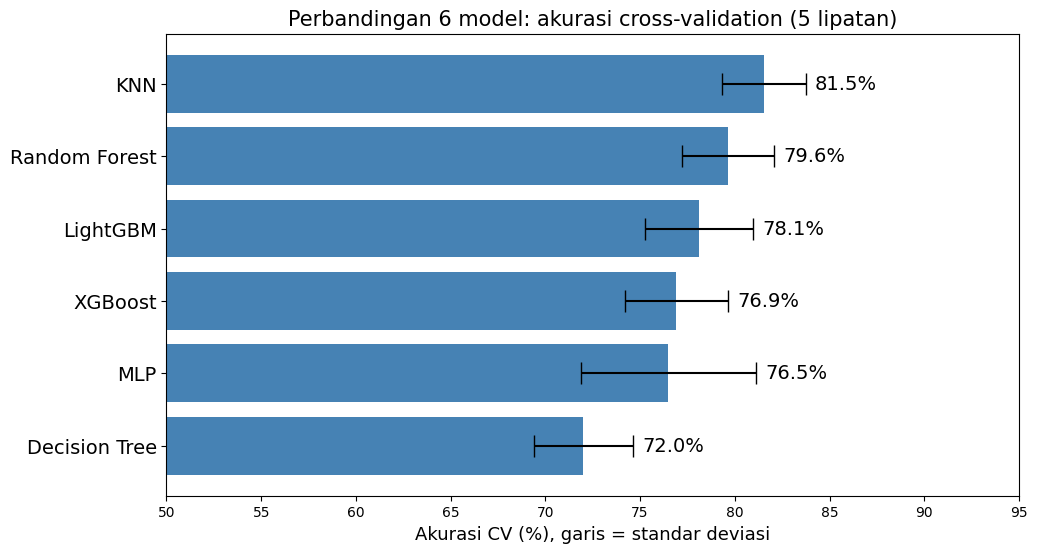

In [ ]:
urut = tabel_model.sort_values("akurasi CV")                          # urut naik, supaya yang terbaik di atas

plt.figure(figsize=(11, 6))
# batang = akurasi CV rata-rata, garis hitam = std (naik-turun antar lipatan)
plt.barh(urut["model"], urut["akurasi CV"] * 100, xerr=urut["std akurasi"] * 100, color="steelblue", capsize=8)
for posisi, (akurasi, std) in enumerate(zip(urut["akurasi CV"] * 100, urut["std akurasi"] * 100)):   # label angka
    plt.text(akurasi + std + 0.5, posisi, f"{akurasi:.1f}%", va="center", fontsize=14)   # tulis di ujung batang
plt.xlim(50, 95)
plt.yticks(fontsize=14)
plt.title("Perbandingan 6 model: akurasi cross-validation (5 lipatan)", fontsize=15)
plt.xlabel("Akurasi CV (%), garis = standar deviasi", fontsize=13)
plt.show()

**Diskusi:** Model mana yang akurasinya tertinggi? Selisihnya dengan Random Forest berapa poin? Sebanding dengan std-nya?

**Diskusi:** Kalau kalian membuat model ini untuk rumah sakit, pilih yang mana?

> **Di dunia nyata (cukup dipahami, tidak dipraktikkan):** Model terpilih dilatih ulang di **seluruh** data latih, lalu dicek **sekali** di data uji sebagai laporan akhir. Model boosting dan MLP biasanya baru unggul jelas setelah di-tuning dan di data yang jauh lebih besar (ribuan sampai jutaan baris). Untuk data tabel kecil seperti ini, model sederhana yang dipilih dengan cermat sering sudah cukup.

## Ringkasan (± 1 menit)
| Langkah | Yang dilakukan | Kode |
|---|---|---|
| 1. Cek train vs test | Kenali overfitting (train jauh di atas test) dan underfitting (dua-duanya rendah) | `accuracy_score` di data latih dan uji |
| 2. Cross-validation | Nilai model di 5 lipatan data latih, bukan satu kali split | `make_pipeline`, `cross_val_score` |
| 3. Tuning | Pilih pengaturan (misalnya k) berdasarkan skor CV | loop atau `GridSearchCV` |
| 4. Bandingkan model | Semua model dengan data, lipatan, dan aturan yang sama | `cross_validate` |
| 5. Pilih | Timbang akurasi, recall, std, dan kemudahan dijelaskan, lalu cek sekali di data uji | |

**Semua langkah ini kalian pakai di Mini Project.**